In [14]:
import os
import cv2
import numpy as np
import tensorflow as tf
from sklearn.utils import shuffle
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import Model
from tensorflow.keras.layers import Dense, Input
from matplotlib import pyplot as plt


plt.rcParams['figure.figsize'] = [15, 6]

### Завантаження, підрахунок та візуалізація даних

Кількість зображень class_0: 2220
Кількість зображень class_1: 2250


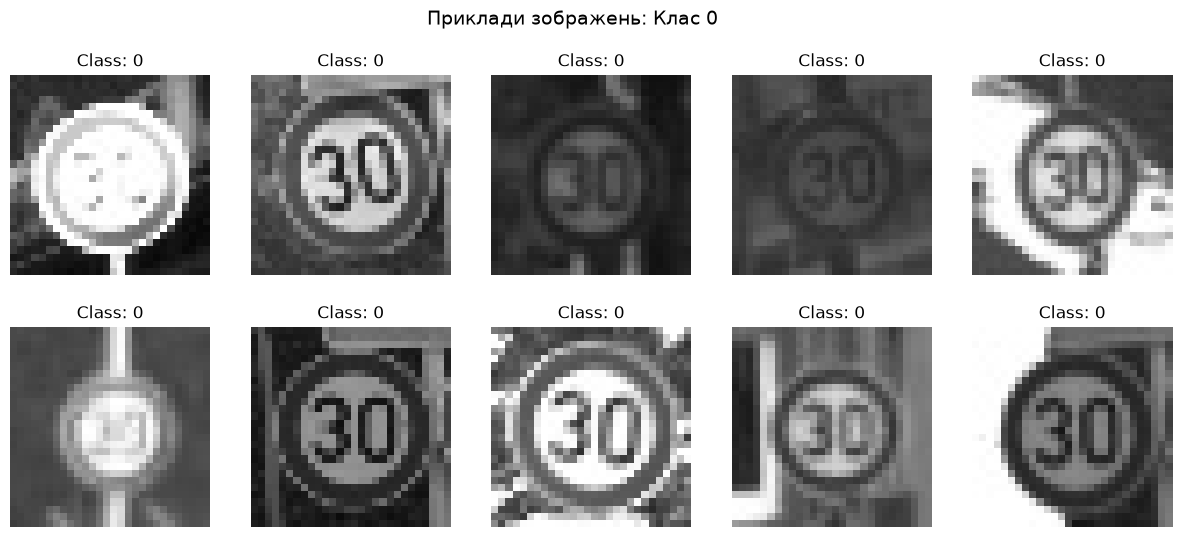

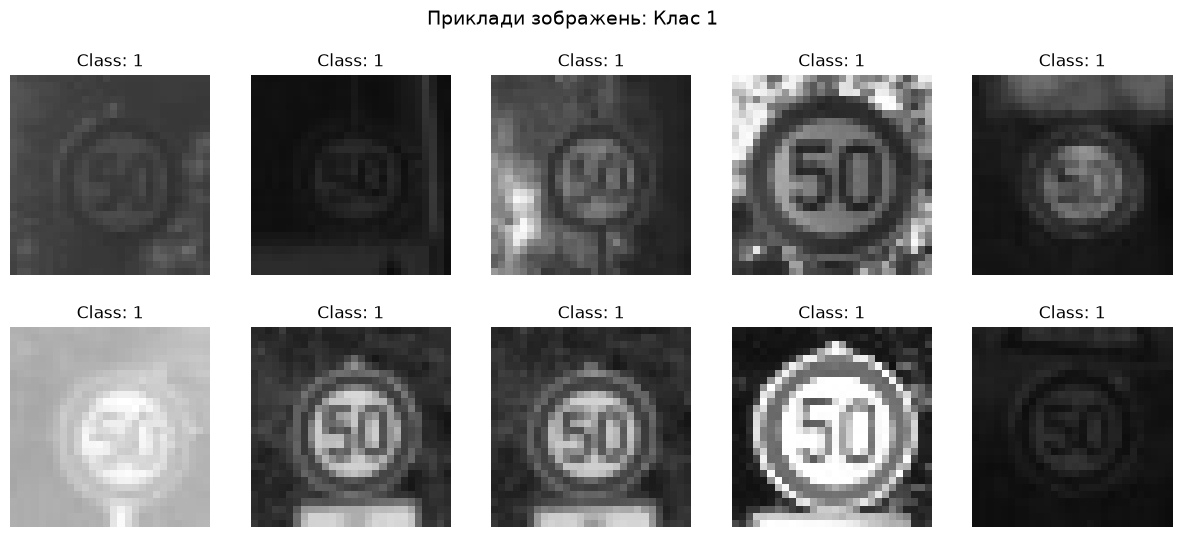

Форма масиву зображень: (4470, 28, 28)
Форма масиву пікселів (вхід мережі): (4470, 784)


In [ ]:
folder = '../data/subset_homework'

# Завантаження класу 0
fnames_0 = os.listdir(os.path.join(folder, 'class_id_0'))
images_0 = [cv2.imread(os.path.join(folder, 'class_id_0', f), cv2.IMREAD_UNCHANGED) for f in fnames_0]
labels_0 = [0] * len(images_0)

# Завантаження класу 1
fnames_1 = os.listdir(os.path.join(folder, 'class_id_1'))
images_1 = [cv2.imread(os.path.join(folder, 'class_id_1', f), cv2.IMREAD_UNCHANGED) for f in fnames_1]
labels_1 = [1] * len(images_1)

print('Кількість зображень class_0:', len(images_0))
print('Кількість зображень class_1:', len(images_1))

# Візуалізація прикладів класу 0
plt.figure()
plt.suptitle('Приклади зображень: Клас 0', fontsize=14)
for cnt, idx in enumerate(np.random.randint(0, len(images_0), 10)):
    plt.subplot(2, 5, cnt + 1)
    plt.imshow(images_0[idx], cmap='gray', vmin=0, vmax=255)
    plt.title(f'Class: {labels_0[idx]}')
    plt.axis(False)
plt.show()

# Візуалізація прикладів класу 1
plt.figure()
plt.suptitle('Приклади зображень: Клас 1', fontsize=14)
for cnt, idx in enumerate(np.random.randint(0, len(images_1), 10)):
    plt.subplot(2, 5, cnt + 1)
    plt.imshow(images_1[idx], cmap='gray', vmin=0, vmax=255)
    plt.title(f'Class: {labels_1[idx]}')
    plt.axis(False)
plt.show()

# Підготовка та перемішування даних
images = images_0 + images_1
labels = labels_0 + labels_1
images, labels = shuffle(images, labels, random_state=42)

images = np.array(images)
labels = np.array(labels)

# Витягування зображень у плоскі вектори та нормалізація [0, 1]
pixels = np.array([image.flatten() for image in images]) / 255.0

print('Форма масиву зображень:', images.shape)
print('Форма масиву пікселів (вхід мережі):', pixels.shape)

### Навчання моделі з одним нейроном

In [ ]:
print('\n--- Навчання моделі з 1 нейроном ---')
inputs_single = Input(shape=(pixels.shape[1],))
outputs_single = Dense(1, activation='linear')(inputs_single)
model_single = Model(inputs_single, outputs_single)
model_single.summary()

model_single.compile(optimizer='adam', loss='mean_squared_error')
history_single = model_single.fit(pixels, labels, epochs=10, batch_size=32, verbose=1)

# Оцінка точності одного нейрона
preds_single = model_single.predict(pixels).squeeze() > 0.5
accuracy_single = np.mean(preds_single == labels)
print(f'Точність (Accuracy) одного нейрона: {accuracy_single:.4f} ({accuracy_single:.2%})')


--- Навчання моделі з 1 нейроном ---


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │           785 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 785 (3.07 KB)

 Trainable params: 785 (3.07 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 662us/step - loss: 0.3038 
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 567us/step - loss: 0.2205
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 591us/step - loss: 0.1818
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 555us/step - loss: 0.1578
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 565us/step - loss: 0.1373
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1285
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1209
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 542us/step - loss: 0.1064
Epoch 9/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 564us/step - loss: 0.1022
Epoch 10/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 541us/step - loss: 0.0976
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 377us/step
Точність (Accuracy) одного нейрона: 0.9043 (90.43%)


### Покращена багатошарова модель

In [ ]:
print('\n--- Навчання покращеної моделі ---')
inputs_imp = Input(shape=(pixels.shape[1],))
x = Dense(128, activation='relu')(inputs_imp)
x = Dense(64, activation='relu')(x)
x = Dense(32, activation='relu')(x)
outputs_imp = Dense(1, activation='sigmoid')(x)

model_improved = Model(inputs_imp, outputs_imp)
model_improved.summary()

model_improved.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_improved = model_improved.fit(
    pixels,
    labels,
    epochs=40,
    batch_size=32,
    verbose=1
)

# Оцінка точності покращеної моделі
raw_preds_imp = model_improved.predict(pixels).squeeze()
preds_imp = (raw_preds_imp > 0.5).astype(int)
accuracy_improved = np.mean(preds_imp == labels)
print(f'Точність (Accuracy) покращеної моделі: {accuracy_improved:.4f} ({accuracy_improved:.2%})')


--- Навчання покращеної моделі ---


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,849 (433.00 KB)

 Trainable params: 110,849 (433.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6530 - loss: 0.6191
Epoch 2/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8179 - loss: 0.4324
Epoch 3/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8913 - loss: 0.2879
Epoch 4/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9074 - loss: 0.2505
Epoch 5/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9000 - loss: 0.2664
Epoch 6/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9425 - loss: 0.1717
Epoch 7/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9400 - loss: 0.1645
Epoch 8/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9237 - loss: 0.2019
Epoch 9/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9438 - loss: 0.1584
Epoch 10/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9519 - loss: 0.1279
Epoch 11/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9517 - loss: 0.1313
Epoch 12/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

### Графіки роботи та аналізу моделей

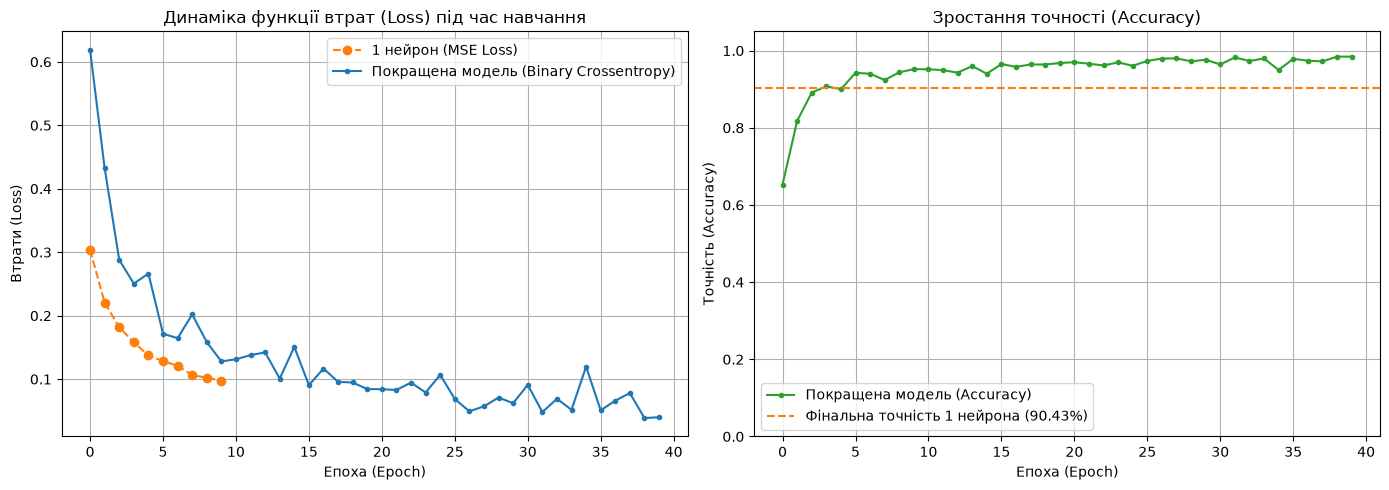

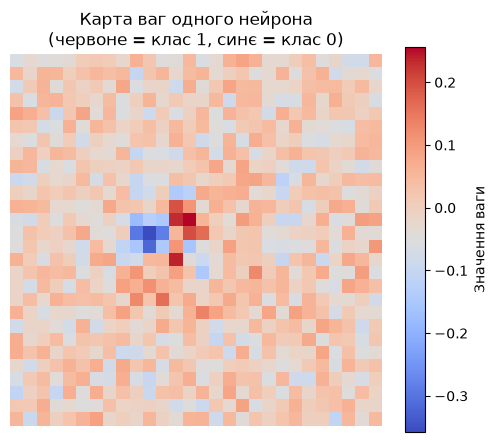

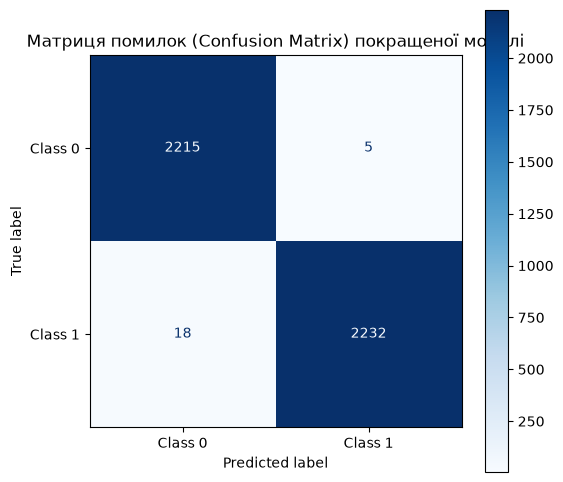

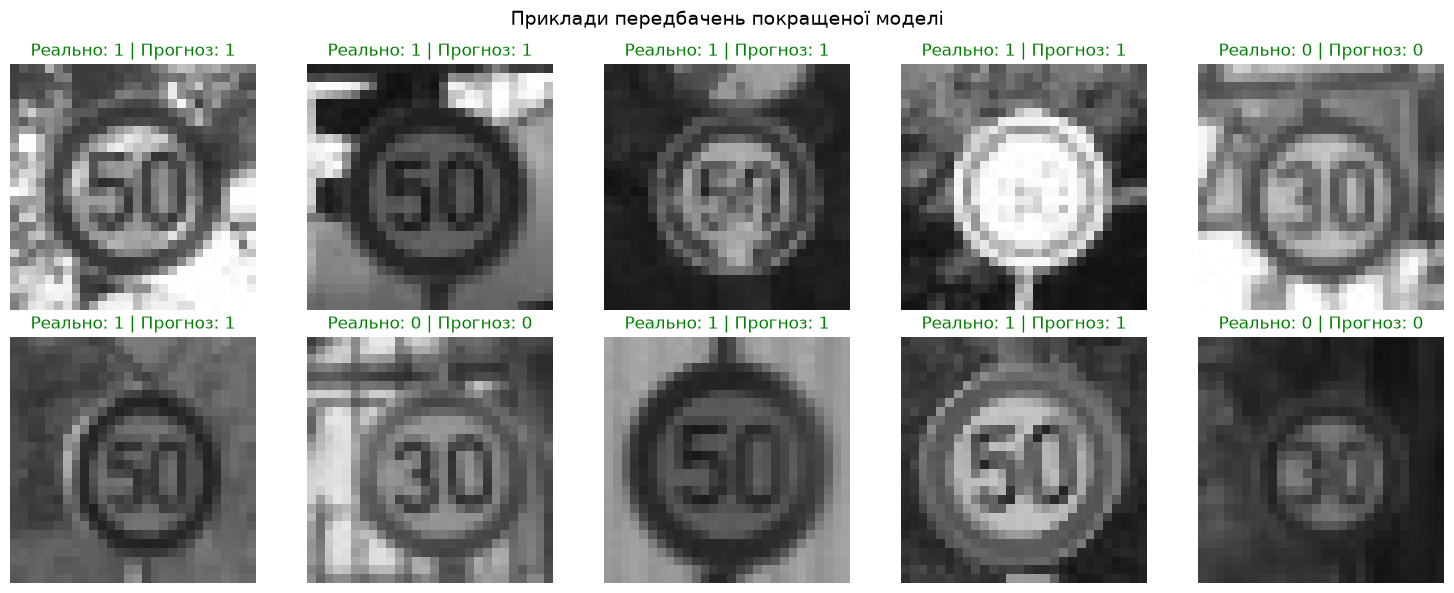

Загальна кількість помилок покращеної моделі: 23 з 4470


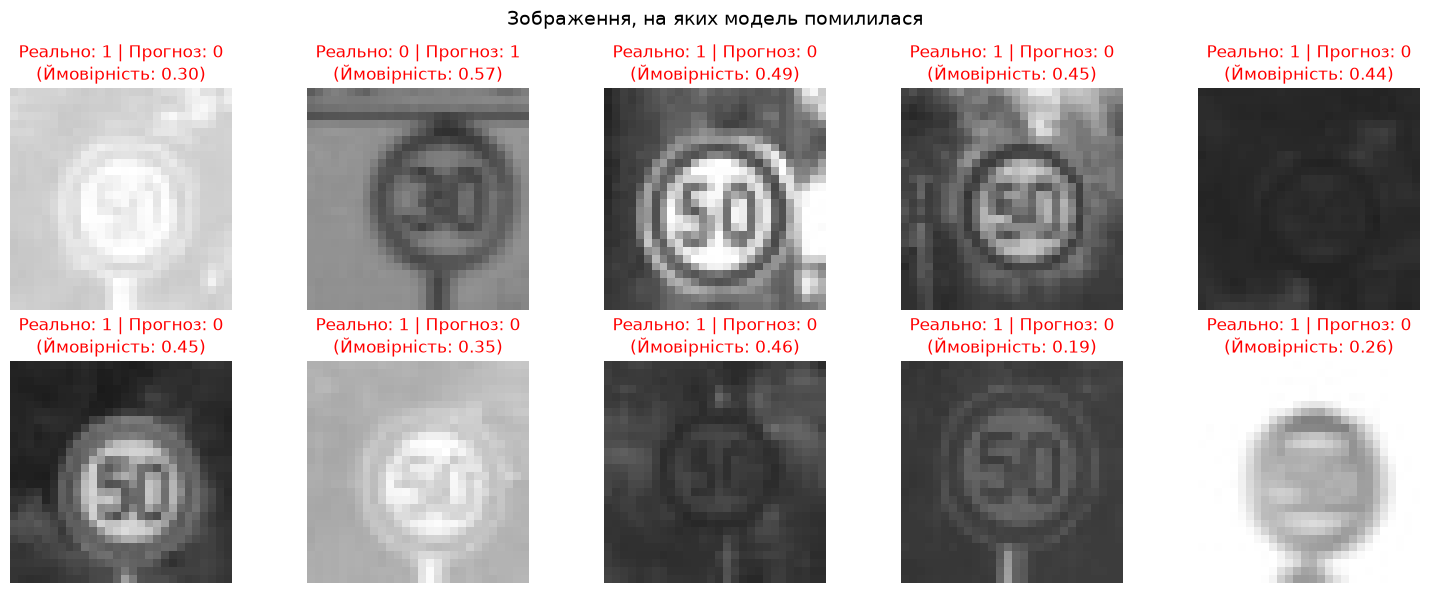

In [ ]:
# 1. Порівняння процесу навчання (Loss та Accuracy)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_single.history['loss'], 'o--', label='1 нейрон (MSE Loss)', color='tab:orange')
plt.plot(history_improved.history['loss'], '.-', label='Покращена модель (Binary Crossentropy)', color='tab:blue')
plt.title('Динаміка функції втрат (Loss) під час навчання')
plt.xlabel('Епоха (Epoch)')
plt.ylabel('Втрати (Loss)')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_improved.history['accuracy'], '.-', label='Покращена модель (Accuracy)', color='tab:green')
plt.axhline(y=accuracy_single, color='tab:orange', linestyle='--', label=f'Фінальна точність 1 нейрона ({accuracy_single:.2%})')
plt.title('Зростання точності (Accuracy)')
plt.xlabel('Епоха (Epoch)')
plt.ylabel('Точність (Accuracy)')
plt.ylim([0, 1.05])
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# 2. Теплова карта ваг одного нейрона
weights = model_single.layers[1].get_weights()[0]
img_shape = images[0].shape
weight_image = weights.reshape(img_shape)

if len(img_shape) == 3:
    weight_image = np.mean(weight_image, axis=-1)

plt.figure(figsize=(6, 5))
plt.imshow(weight_image, cmap='coolwarm')
plt.colorbar(label='Значення ваги')
plt.title('Карта ваг одного нейрона\n(червоне = клас 1, синє = клас 0)')
plt.axis(False)
plt.show()

# 3. Матриця помилок (Confusion Matrix) для покращеної моделі
cm = confusion_matrix(labels, preds_imp)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0', 'Class 1'])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Матриця помилок (Confusion Matrix) покращеної моделі')
plt.grid(False)
plt.show()

# 4. Візуалізація випадкових прогнозів покращеної моделі
plt.figure(figsize=(15, 6))
plt.suptitle('Приклади передбачень покращеної моделі', fontsize=14)
for cnt, idx in enumerate(np.random.randint(0, len(images), 10)):
    plt.subplot(2, 5, cnt + 1)
    plt.imshow(images[idx], cmap='gray', vmin=0, vmax=255)
    color = 'green' if preds_imp[idx] == labels[idx] else 'red'
    plt.title(f'Реально: {labels[idx]} | Прогноз: {preds_imp[idx]}', color=color)
    plt.axis(False)
plt.tight_layout()
plt.show()

# 5. Візуалізація помилкових передбачень (якщо вони є)
error_indices = np.where(preds_imp != labels)[0]
print(f'Загальна кількість помилок покращеної моделі: {len(error_indices)} з {len(labels)}')

if len(error_indices) > 0:
    plt.figure(figsize=(15, 6))
    plt.suptitle('Зображення, на яких модель помилилася', fontsize=14)
    for cnt, idx in enumerate(error_indices[:10]):
        plt.subplot(2, 5, cnt + 1)
        plt.imshow(images[idx], cmap='gray', vmin=0, vmax=255)
        plt.title(f'Реально: {labels[idx]} | Прогноз: {preds_imp[idx]}\n(Ймовірність: {raw_preds_imp[idx]:.2f})', color='red')
        plt.axis(False)
    plt.tight_layout()
    plt.show()
else:
    print('Покращена модель не зробила жодної помилки!')